In [5]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import matplotlib

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [62]:
# ------------------------------------------------------------
# Physical constants
# ------------------------------------------------------------

k_B = 1.380649e-16          # Boltzmann constant, erg K^-1
keV_to_erg = 1.602176634e-9 # 1 keV in erg
m_p = 1.67262192369e-24     # proton mass, g
Mpc_to_cm = 3.0856e24       # Mpc in cm


# ------------------------------------------------------------
# Density profile: beta model
# ------------------------------------------------------------

def beta_density_profile(r_kpc, n0=1e-3, rc_kpc=10.0, beta=0.5):
    """
    Electron number density profile in cm^-3.
    """
    return n0 * (1.0 + (r_kpc / rc_kpc) ** 2) ** (-1.5 * beta)


# ------------------------------------------------------------
# Temperature profile
# ------------------------------------------------------------

def temperature_profile(
    r_kpc,
    T_inner=2.0e7,
    T_outer=8.0e6,
    rt_kpc=100.0,
    slope=2.0,
):
    """
    Gas temperature profile in Kelvin.
    """
    return T_outer + (T_inner - T_outer) / (1.0 + (r_kpc / rt_kpc) ** slope)


def temperature_K_to_keV(T_K):
    """
    Convert temperature from Kelvin to keV.

    k_B T in keV = k_B * T_K / keV_to_erg
    """
    return k_B * T_K / keV_to_erg


# ------------------------------------------------------------
# Metallicity profile
# ------------------------------------------------------------

def metallicity_profile(
    r_kpc,
    Z0=0.5,
    Z_floor=0.1,
    rZ_kpc=50.0,
    gamma=1.5,
):
    """
    Gas metallicity profile in solar units.
    """
    return Z_floor + (Z0 - Z_floor) / (1.0 + (r_kpc / rZ_kpc) ** gamma)


# ------------------------------------------------------------
# Pressure profile
# ------------------------------------------------------------

def pressure_profile_from_ne_T(
    n_e,
    T_K,
    mu=0.62,
    mu_e=1.17,
):
    """
    Thermal pressure profile from electron density and temperature.

    Returns
    -------
    P : array-like
        Thermal pressure in erg cm^-3.
    P_over_kB : array-like
        Pressure divided by Boltzmann constant in K cm^-3.
    n_tot : array-like
        Total particle number density in cm^-3.
    """
    P_e = n_e * k_B * T_K

    return P_e



In [63]:
# ------------------------------------------------------------
# Radial grid
# ------------------------------------------------------------

r_kpc = np.logspace(1, 3, 500)  # 10 kpc to 1000 kpc

# ------------------------------------------------------------
# Evaluate profiles
# ------------------------------------------------------------

n_e = beta_density_profile(
    r_kpc,
    n0=1e-3,
    rc_kpc=10.0,
    beta=0.5,
)

T_K = temperature_profile(
    r_kpc,
    T_inner=2.0e6,
    T_outer=8.0e5,
    rt_kpc=100.0,
    slope=2.0,
)

T_keV = temperature_K_to_keV(T_K)

Z = metallicity_profile(
    r_kpc,
    Z0=0.5,
    Z_floor=0.1,
    rZ_kpc=50.0,
    gamma=1.5,
)

P_e = pressure_profile_from_ne_T(
    n_e,
    T_K,
    mu=0.62,
    mu_e=1.17,
)

rho_gas = 1.17 * m_p * n_e  # g cm^-3

In [64]:
from cgm_toolkit import cgm_profiles

In [65]:
redshift = 0.1
halo_pro = cgm_profiles.HaloProfile(redshift, r_kpc, P_e, n_e, Z, temperature=T_keV)

In [66]:
xray_emissivity_profile = halo_pro.spherical_xray_emissivity_profile(r_kpc, etable='../data/etable_05_2keV_3D.hdf5')
xsb_profile = halo_pro.projected_xray_surface_brightness_profile (r_kpc, etable='../data/etable_05_2keV_3D.hdf5')
xsb_profile = xsb_profile * (4.0*np.pi) * Mpc_to_cm**2 

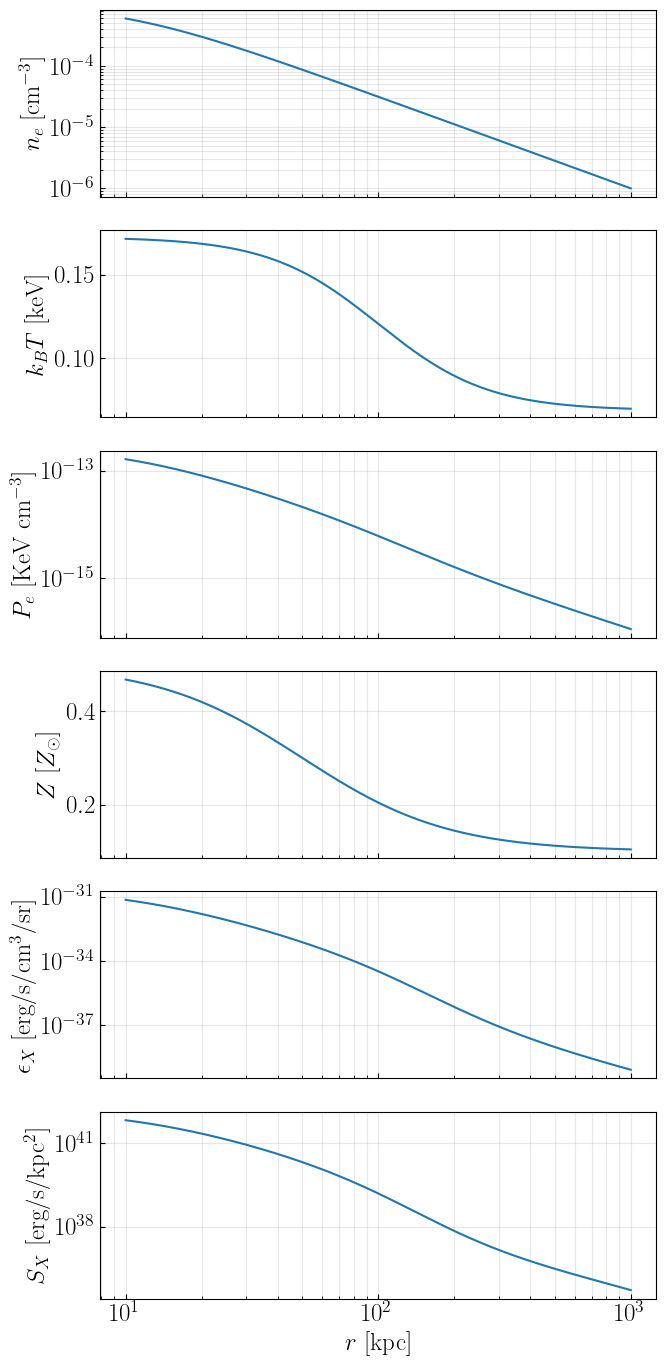

In [67]:
# ------------------------------------------------------------
# Plot profiles
# ------------------------------------------------------------

fig, axes = plt.subplots(6, 1, figsize=(7, 14), sharex=True)

axes[0].loglog(r_kpc, n_e)
axes[0].set_ylabel(r"$n_e$ [cm$^{-3}$]")
axes[0].grid(True, which="both", alpha=0.3)

axes[1].semilogx(r_kpc, T_keV)
axes[1].set_ylabel(r"$k_B T$ [keV]")
axes[1].grid(True, which="both", alpha=0.3)

axes[2].loglog(r_kpc, P_e)
axes[2].set_ylabel(r"$P_e$ [KeV cm$^{-3}$]")
axes[2].grid(True, which="both", alpha=0.3)

axes[3].semilogx(r_kpc, Z)
axes[3].set_ylabel(r"$Z$ [$Z_\odot$]")
axes[3].grid(True, which="both", alpha=0.3)

axes[4].loglog(r_kpc, xray_emissivity_profile)
axes[4].set_ylabel(r"$\epsilon_X$ [erg/s/cm$^{3}$/sr]")
axes[4].grid(True, which="both", alpha=0.3)

axes[5].loglog(r_kpc, xsb_profile)
axes[5].set_xlabel(r"$r$ [kpc]")
axes[5].set_ylabel(r"$S_X$ [erg/s/kpc$^{2}$]")
axes[5].grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()